# 01 — Local Mac Experiments

This notebook analyzes the local Mac runs for the three implementations in the unified CSR framework: serial `1×1`, MPI-only `4×1`, and MPI+OpenMP `2×2`. Each data-set/configuration pair uses one warm-up followed by five measured runs; tables and plots report medians. Multi-node scaling is reported in `02_vanda_experiments.ipynb`.


In [1]:
from pathlib import Path
import os

ROOT = Path.cwd().resolve()
if not (ROOT / 'Makefile').exists():
    ROOT = ROOT.parent
assert (ROOT / 'Makefile').exists(), 'Start Jupyter from the project directory or its notebook subdirectory'
os.chdir(ROOT)
print('Project root located; working directory set successfully.')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATASET_ORDER = ['web-Google', 'web-BerkStan', 'enwiki-2013', 'uk-2002']
MODE_ORDER = ['serial', 'mpi', 'hybrid']
COLORS = {'serial': '#4C78A8', 'mpi': '#F58518', 'hybrid': '#54A24B'}
RESULT_FILE = ROOT / 'results/local/mac_full_run_20261107.csv'
assert RESULT_FILE.exists(), RESULT_FILE
print('Result file:', RESULT_FILE.relative_to(ROOT))


Project root located; working directory set successfully.


Result file: results/local/mac_full_run_20261107.csv


## 1. Experimental Design

The machine is an Apple M3 Pro with 11 CPU cores and 18 GiB RAM. Parameters are `alpha=0.85`, global L1 tolerance `1e-12`, and at most 1,000 iterations. Each configuration has one unrecorded warm-up and five measured runs. Performance comparisons use median `solve_seconds`, excluding loading, distribution, and validation.

| Implementation | R×T | Workers |
|---|---:|---:|
| Serial | 1×1 | 1 |
| MPI only | 4×1 | 4 |
| MPI+OpenMP | 2×2 | 4 |


## 2. Load and Validate Results

In [2]:
runs = pd.read_csv(RESULT_FILE)
runs['dataset_name'] = runs['dataset'].map(lambda value: Path(value).stem)
runs['config'] = runs['mpi_ranks'].astype(str) + '×' + runs['threads_per_rank'].astype(str)
runs['workers'] = runs['mpi_ranks'] * runs['threads_per_rank']

per_configuration = runs.groupby(['dataset_name', 'mode']).size()
checks = pd.Series({
    'rows': len(runs),
    'datasets': runs['dataset_name'].nunique(),
    'implementations': runs['mode'].nunique(),
    'runs_per_configuration_min': per_configuration.min(),
    'runs_per_configuration_max': per_configuration.max(),
    'all_converged': runs['converged'].eq(1).all(),
    'max_residual': runs['residual'].max(),
    'max_rank_sum_error': runs['rank_sum_error'].max(),
    'max_parallel_L1_error': runs.loc[runs['mode'].ne('serial'), 'serial_l1_error'].max(),
})
display(checks.to_frame('value'))
assert len(runs) == 60
assert per_configuration.eq(5).all()
assert checks['all_converged'] and checks['max_rank_sum_error'] < 1e-9


,value
rows,60
datasets,4
implementations,3
runs_per_configuration_min,5
runs_per_configuration_max,5
all_converged,True
max_residual,0.0
max_rank_sum_error,0.0
max_parallel_L1_error,0


## 3. Results Table

In [3]:
summary = (runs.groupby(['dataset_name', 'mode'], as_index=False)
           .agg(vertices=('vertices', 'first'), edges=('edges', 'first'),
                config=('config', 'first'), workers=('workers', 'first'),
                iterations=('iterations', 'first'),
                solve_seconds=('solve_seconds', 'median'),
                solve_min=('solve_seconds', 'min'), solve_max=('solve_seconds', 'max'),
                residual=('residual', 'max')))
serial_time = (summary[summary['mode'].eq('serial')]
               .set_index('dataset_name')['solve_seconds'])
summary['serial_s'] = summary['dataset_name'].map(serial_time)
summary['speedup'] = summary['serial_s'] / summary['solve_seconds']
summary['efficiency'] = summary['speedup'] / summary['workers']
summary['dataset_name'] = pd.Categorical(summary['dataset_name'], DATASET_ORDER, ordered=True)
summary['mode'] = pd.Categorical(summary['mode'], MODE_ORDER, ordered=True)
summary = summary.sort_values(['dataset_name', 'mode'])

table = summary[['dataset_name', 'vertices', 'edges', 'mode', 'config', 'iterations',
                 'solve_seconds', 'solve_min', 'solve_max', 'speedup',
                 'efficiency', 'residual']].copy()
table['vertices'] = table['vertices'].map('{:,}'.format)
table['edges'] = table['edges'].map('{:,}'.format)
for column in ['solve_seconds', 'solve_min', 'solve_max']:
    table[column] = table[column].map('{:.3f}'.format)
table['speedup'] = table['speedup'].map('{:.2f}×'.format)
table['efficiency'] = table['efficiency'].map('{:.1%}'.format)
table['residual'] = table['residual'].map('{:.2e}'.format)
display(table)


,dataset_name,vertices,edges,mode,config,iterations,solve_seconds,solve_min,solve_max,speedup,efficiency,residual
11,web-Google,"875,713","5,105,039",serial,1×1,146,1.644,1.640,1.700,1.00×,100.0%,7.54e-13
10,web-Google,"875,713","5,105,039",mpi,4×1,146,2.899,2.874,3.022,0.57×,14.2%,7.55e-13
9,web-Google,"875,713","5,105,039",hybrid,2×2,146,1.534,1.513,1.545,1.07×,26.8%,7.55e-13
8,web-BerkStan,"685,230","7,600,595",serial,1×1,148,0.894,0.890,0.907,1.00×,100.0%,7.81e-13
7,web-BerkStan,"685,230","7,600,595",mpi,4×1,148,0.849,0.827,0.932,1.05×,26.3%,7.81e-13
6,web-BerkStan,"685,230","7,600,595",hybrid,2×2,148,0.597,0.596,0.628,1.50×,37.4%,7.81e-13
2,enwiki-2013,"4,203,323","101,311,614",serial,1×1,95,24.717,23.435,26.272,1.00×,100.0%,7.54e-13
1,enwiki-2013,"4,203,323","101,311,614",mpi,4×1,95,19.012,18.887,19.790,1.30×,32.5%,7.54e-13
0,enwiki-2013,"4,203,323","101,311,614",hybrid,2×2,95,16.225,16.099,16.567,1.52×,38.1%,7.54e-13
5,uk-2002,"18,520,486","298,113,762",serial,1×1,141,37.192,36.865,44.385,1.00×,100.0%,8.22e-13


## 4. Local Runtime, Speedup, and Efficiency

Bars show five-run medians and runtime whiskers span the measured minimum to maximum. Runtime uses a logarithmic y-axis; the `1×` speedup line marks serial performance. These local measurements characterize the Mac workflow but are not evidence of multi-node scalability.


Saved: results/local/mac_full_run_20261107.png


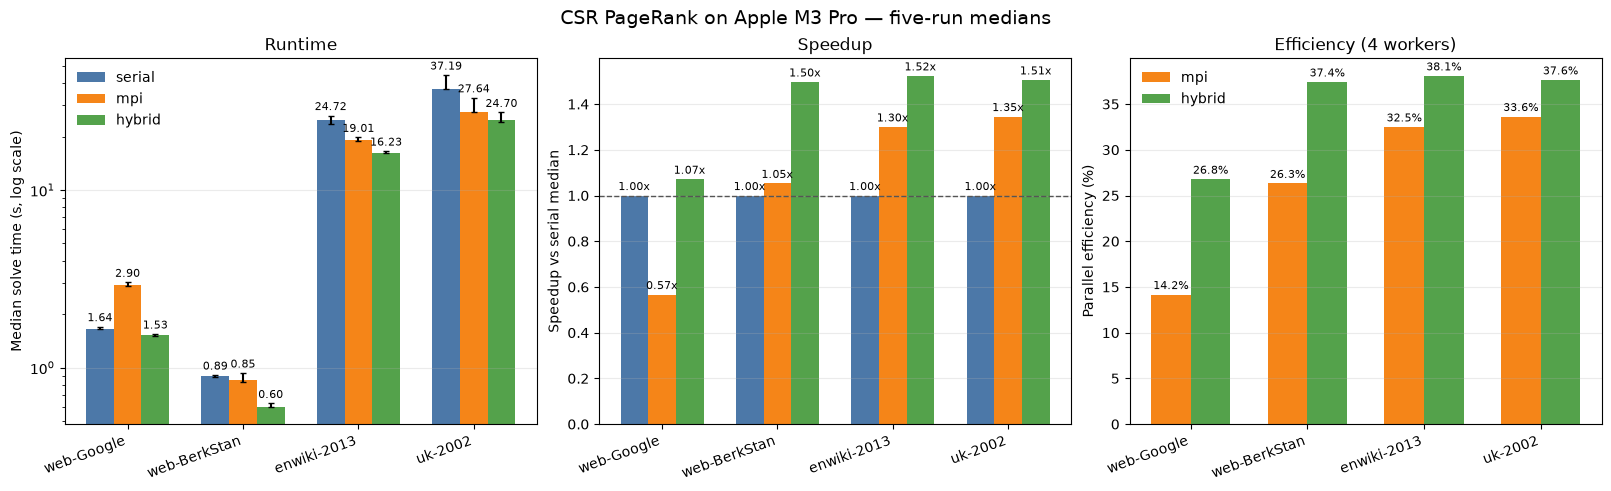

In [4]:
x = np.arange(len(DATASET_ORDER))
width = 0.24
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)

for i, mode in enumerate(MODE_ORDER):
    part = summary[summary['mode'].eq(mode)].set_index('dataset_name').reindex(DATASET_ORDER)
    errors = np.vstack([part['solve_seconds'] - part['solve_min'],
                        part['solve_max'] - part['solve_seconds']])
    bars = axes[0].bar(x + (i - 1) * width, part['solve_seconds'], width,
                       yerr=errors, capsize=2, label=mode, color=COLORS[mode])
    axes[0].bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
axes[0].set_yscale('log')
axes[0].set_ylabel('Median solve time (s, log scale)')
axes[0].set_title('Runtime')
axes[0].legend(frameon=False)

for i, mode in enumerate(MODE_ORDER):
    part = summary[summary['mode'].eq(mode)].set_index('dataset_name').reindex(DATASET_ORDER)
    bars = axes[1].bar(x + (i - 1) * width, part['speedup'], width,
                       label=mode, color=COLORS[mode])
    axes[1].bar_label(bars, fmt='%.2fx', fontsize=8, padding=2)
axes[1].axhline(1.0, color='#555555', linestyle='--', linewidth=1)
axes[1].set_ylabel('Speedup vs serial median')
axes[1].set_title('Speedup')

for i, mode in enumerate(['mpi', 'hybrid']):
    part = summary[summary['mode'].eq(mode)].set_index('dataset_name').reindex(DATASET_ORDER)
    bars = axes[2].bar(x + (i - 0.5) * 0.34, 100 * part['efficiency'], 0.34,
                       label=mode, color=COLORS[mode])
    axes[2].bar_label(bars, fmt='%.1f%%', fontsize=8, padding=2)
axes[2].set_ylabel('Parallel efficiency (%)')
axes[2].set_title('Efficiency (4 workers)')
axes[2].legend(frameon=False)

for ax in axes:
    ax.set_xticks(x, DATASET_ORDER, rotation=20, ha='right')
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('CSR PageRank on Apple M3 Pro — five-run medians', fontsize=14)
figure_path = ROOT / 'results/local/mac_full_run_20261107.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
print('Saved:', figure_path.relative_to(ROOT))
plt.show()


## 5. Observations

- The table and figure use five-run medians rather than individual timings; whiskers expose local run-to-run variation.
- Communication and synchronization can exceed the parallel benefit on a single workstation, especially for smaller graphs.
- A shared-memory Mac cannot characterize multi-node communication. The Vanda medians in the next notebook support the scaling conclusions.

Local reproduction command (one warm-up and five measured runs by default):

```bash
./scripts/run_all_modes.sh data/processed/web-Google.prcsr 5 4 2 2
```
